### The overall Process/Stages for Creating a LLM from scratch
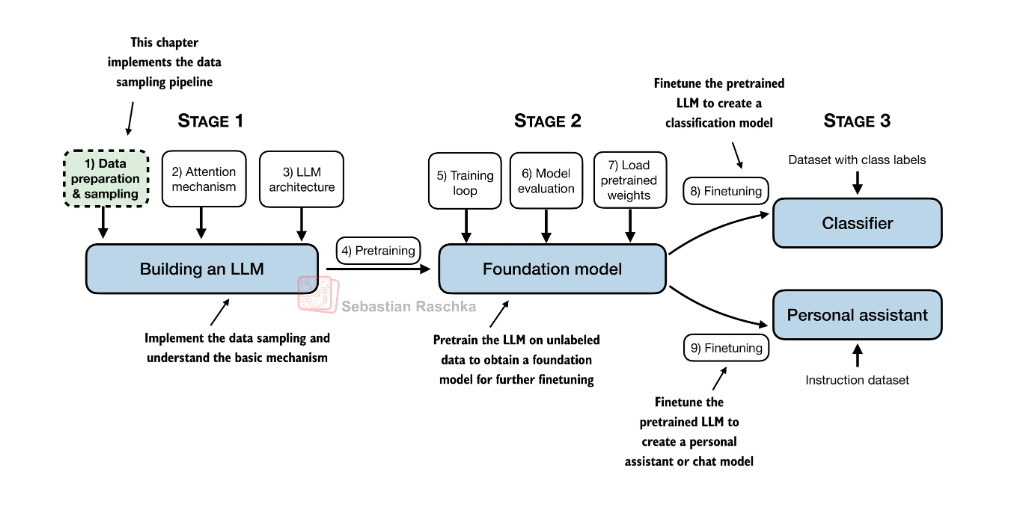

### Stages for preparing Data to train the LLM:
    - Raw Input Text
    - Tokenize the Raw Input Text [for eg BytePair Tokenization ALgorithm]
    - We get the corresponding Token-ids from prev step
    - We create a Vocabulary [Vocabulary is a Python Dictionary consisting of key-value Pairs , where { key = Token Value (the word) } and { Value = corresponding Token Id's generated }]
    - Generate Token Embeddings [Vector Embeddings - That capture the "Semantic" Meaning]

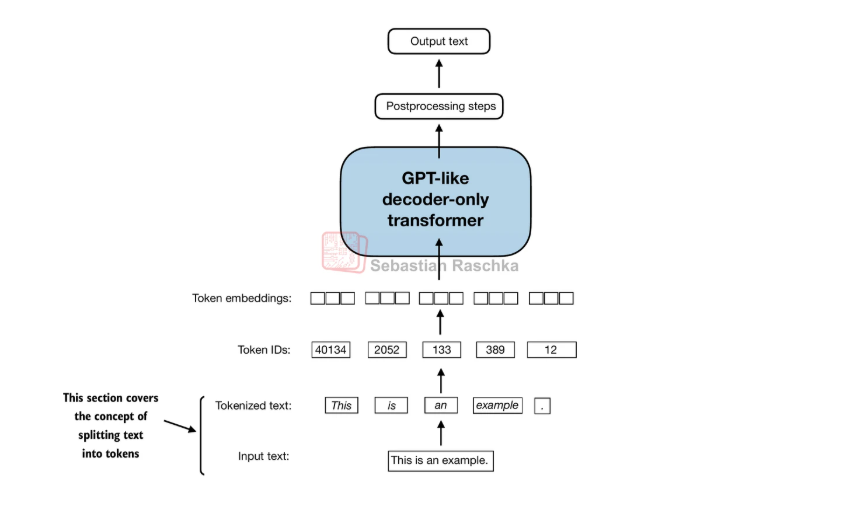

### Below is how the vocabulary looks after Tokenization of i/p text:

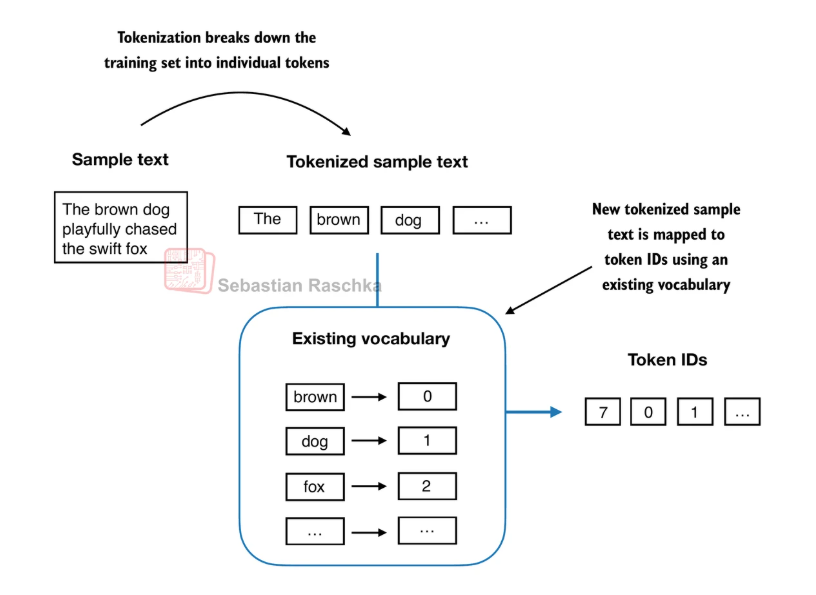

### Below is the Encode and Decode functionality of Tokenization:

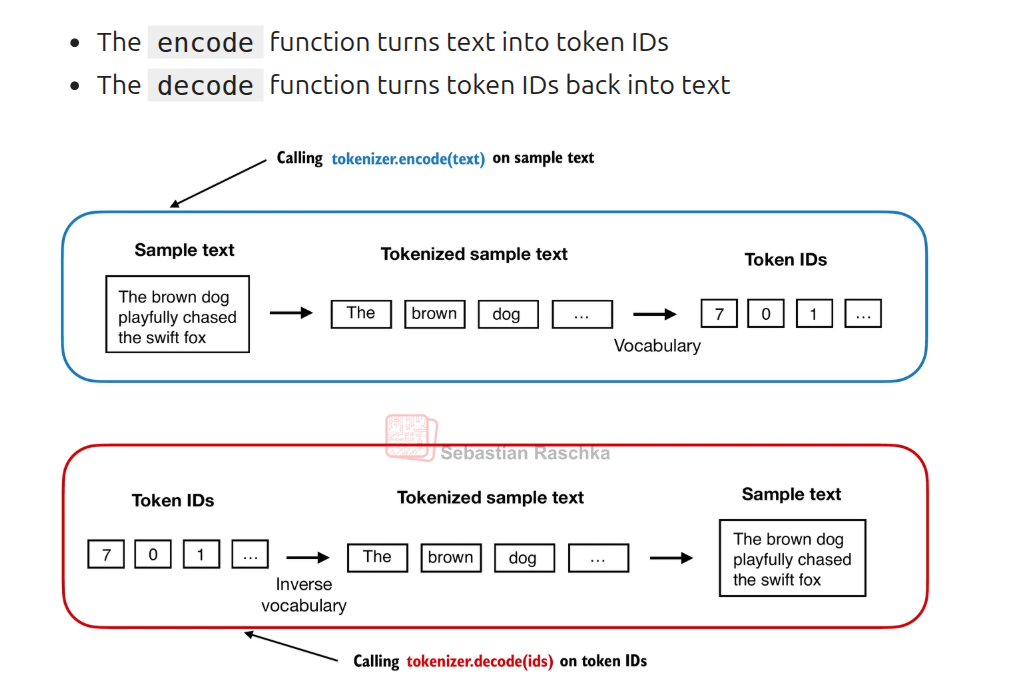

### Adding special Tokens for OOV(Out of Vocabulary words) and other Parameters:
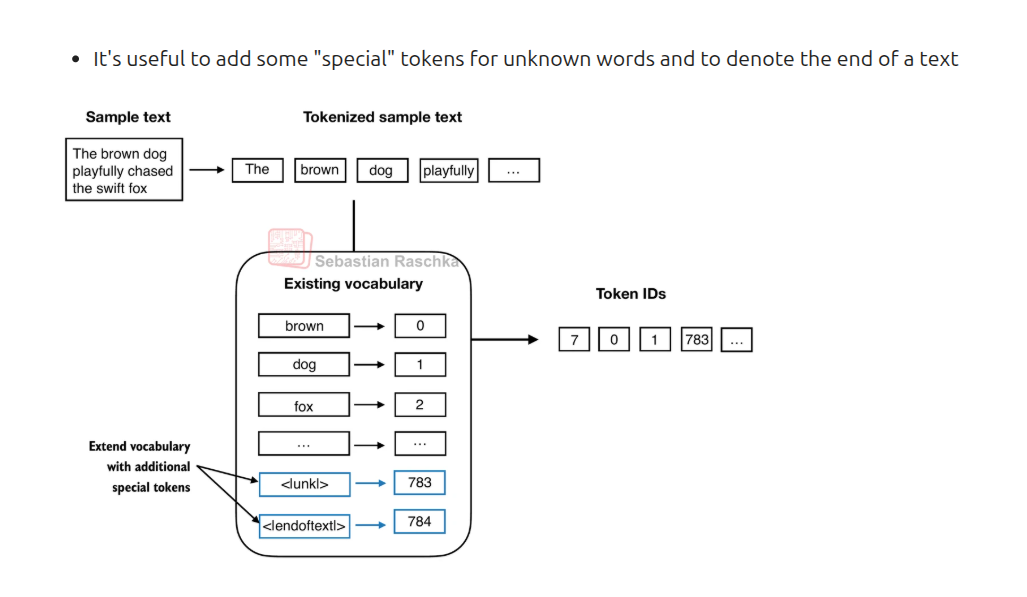

### Example of some Special Tokens and there use:
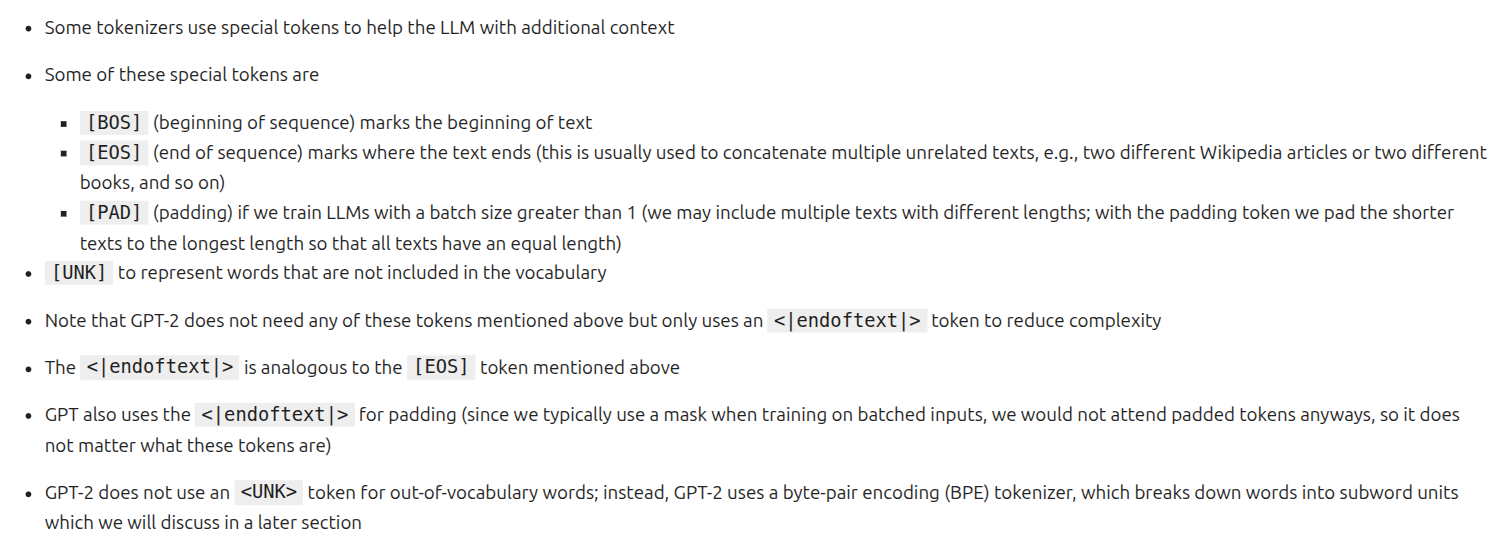

In [4]:
import re

# Import the raw data:
with open(
    "/home/meet/Desktop/self_project/LLM_From_scratch/the-verdict.txt",
    "r",
    encoding="utf-8",
) as f:
    raw_text = f.read()


# Preprocess the raw text to create a vocabulary and strip whitespace:
preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', raw_text)
preprocessed = [item.strip() for item in preprocessed if item.strip()]
print(preprocessed[:30])
print("Length of preprocessed text after tokenization : " , len(preprocessed))


# From these tokens, we can now build a vocabulary that consists of all the unique tokens
all_words = sorted(set(preprocessed))


# create a dictionary that maps each unique token to a unique integer ID
vocab = {token: integer for integer, token in enumerate(all_words)}
print("Length of vocabulary before adding special tokens : ", len(vocab.items()))


# Below are the first 20 entries in this vocabulary:
for token, integer in list(vocab.items())[:20]:
    print(f"{token}: {integer}")


# adding a special token for unknown words and end of text:
all_tokens = sorted(list(set(preprocessed)))
all_tokens.extend(["<|endoftext|>", "<|unk|>"])
vocab = {token: integer for integer, token in enumerate(all_tokens)}

print("Length of vocabulary adding adding special tokens : ", len(vocab.items()))

# Last 5 entries of new vocabulary:
for i, item in enumerate(list(vocab.items())[-5:]):
    print("new vocab : ",item)

class SimpleTokenizerV2:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = {i: s for s, i in vocab.items()}

    def encode(self, text):
        preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', text)
        preprocessed = [item.strip() for item in preprocessed if item.strip()]
        preprocessed = [
            item if item in self.str_to_int else "<|unk|>" for item in preprocessed
        ]

        ids = [self.str_to_int[s] for s in preprocessed]
        return ids

    def decode(self, ids):
        text = " ".join([self.int_to_str[i] for i in ids])
        # Replace spaces before the specified punctuations
        text = re.sub(r'\s+([,.:;?!"()\'])', r"\1", text)
        return text


['I', 'HAD', 'always', 'thought', 'Jack', 'Gisburn', 'rather', 'a', 'cheap', 'genius', '--', 'though', 'a', 'good', 'fellow', 'enough', '--', 'so', 'it', 'was', 'no', 'great', 'surprise', 'to', 'me', 'to', 'hear', 'that', ',', 'in']
Length of preprocessed text after tokenization :  4690
Length of vocabulary before adding special tokens :  1130
!: 0
": 1
': 2
(: 3
): 4
,: 5
--: 6
.: 7
:: 8
;: 9
?: 10
A: 11
Ah: 12
Among: 13
And: 14
Are: 15
Arrt: 16
As: 17
At: 18
Be: 19
Length of vocabulary adding adding special tokens :  1132
new vocab :  ('younger', 1127)
new vocab :  ('your', 1128)
new vocab :  ('yourself', 1129)
new vocab :  ('<|endoftext|>', 1130)
new vocab :  ('<|unk|>', 1131)


In [ ]:
# Visualizing the new end of text token in the vocabulary:
tokenizer = SimpleTokenizerV2(vocab)

text1 = "Hello, do you like tea?"
text2 = "In the sunlit terraces of the palace."

text = " <|endoftext|> ".join((text1, text2))
print(text)

# encoding the text using the tokenizer v2:
encoded_text = tokenizer.encode(text)
print("Encoded text : ", encoded_text)

# decoding the encoded text using the tokenizer v2:
decoded_text = tokenizer.decode(encoded_text)
print("Decoded text : ", decoded_text)


Hello, do you like tea? <|endoftext|> In the sunlit terraces of the palace.
Encoded text :  [1131, 5, 355, 1126, 628, 975, 10, 1130, 55, 988, 956, 984, 722, 988, 1131, 7]
Decoded text :  <|unk|>, do you like tea? <|endoftext|> In the sunlit terraces of the <|unk|>.


### BytePair encoding
    - GPT-2 used BytePair encoding (BPE) as its tokenizer it allows the model to break down words that aren't in its predefined vocabulary into smaller subword units or even individual characters, enabling it to handle out-of-vocabulary words
    - For instance, if GPT-2's vocabulary doesn't have the word "unfamiliarword," it might tokenize it as ["unfam", "iliar", "word"] or some other subword breakdown, depending on its trained BPE merges
    - The original BPE tokenizer can be found here: https://github.com/openai/gpt-2/blob/master/src/encoder.py
    - In this chapter, we are using the BPE tokenizer from OpenAI's open-source tiktoken library, which implements its core algorithms in Rust to improve computational performance

In [1]:
# pip install tiktoken
import importlib
import tiktoken
import torch

print("tiktoken version:", importlib.metadata.version("tiktoken"))


/home/meet/Desktop/self_project/LLM_From_scratch/.venv/lib/python3.12/site-packages/torch/_subclasses/functional_tensor.py:368: UserWarning: Failed to initialize NumPy: No module named 'numpy' (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:84.)
  cpu = _conversion_method_template(device=torch.device("cpu"))


tiktoken version: 0.14.0


In [2]:
tokenizer = tiktoken.get_encoding("gpt2")

text = (
    "Hello, do you like tea? <|endoftext|> In the sunlit terracesof someunknownPlace."
)

integers = tokenizer.encode(text, allowed_special={"<|endoftext|>"})
print(integers)

strings = tokenizer.decode(integers)
print(strings)


[15496, 11, 466, 345, 588, 8887, 30, 220, 50256, 554, 262, 4252, 18250, 8812, 2114, 1659, 617, 34680, 27271, 13]
Hello, do you like tea? <|endoftext|> In the sunlit terracesof someunknownPlace.


### Data sampling with a sliding window
    We train LLMs to generate one word at a time, so we want to prepare the training data accordingly where the next word in a sequence represents the target to predict:

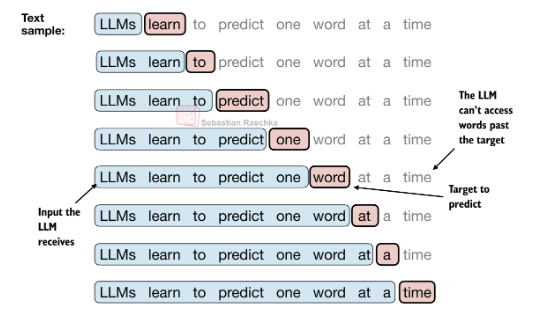

In [3]:
with open(
    "/home/meet/Desktop/self_project/LLM_From_scratch/the-verdict.txt",
    "r",
    encoding="utf-8",
) as f:
    raw_text = f.read()

enc_text = tokenizer.encode(raw_text)
print(len(enc_text))


5145


In [4]:
enc_sample = enc_text[50:]

# Since we want the model to predict the next word, the targets are the inputs shifted by one position to the right
# so if data = a b c d e , input = a b c d and target = b c d e

context_Size = 4
x = enc_sample[:context_Size]
y = enc_sample[1 : context_Size + 1]

print(f"x: {x}")
print(f"y:      {y}")


x: [290, 4920, 2241, 287]
y:      [4920, 2241, 287, 257]


In [5]:
# Everything left of the arrow (---->) refers to the input an LLM would receive, and the token ID on the right side of the arrow represents the target token ID that the LLM is supposed to predict.

for i in range(1, context_Size + 1):
    context = enc_sample[:i]
    desired = enc_sample[i]

    print(context, "---->", desired)


[290] ----> 4920
[290, 4920] ----> 2241
[290, 4920, 2241] ----> 287
[290, 4920, 2241, 287] ----> 257


In [6]:
for i in range(1, context_Size + 1):
    context = enc_sample[:i]
    desired = enc_sample[i]

    print(tokenizer.decode(context), "---->", tokenizer.decode([desired]))


 and ---->  established
 and established ---->  himself
 and established himself ---->  in
 and established himself in ---->  a


### We implement a simple data loader that iterates over the input dataset and returns the inputs and targets shifted by one

    Step 1: Tokenize the entire text

    Step 2: Use a sliding window to chunk the book into overlapping sequences of max_length
    
    Step 3: Return the total number of rows in the dataset
    
    Step 4: Return a single row from the dataset

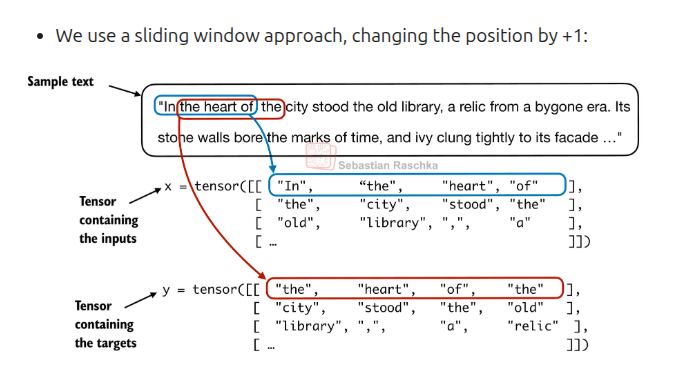

In [7]:
from torch.utils.data import Dataset, DataLoader


class GPTDatasetv1(Dataset):
    def __init__(self, text, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []

        # tokenizing the entire text
        token_ids = tokenizer.encode(text, allowed_special={"<|endoftext|>"})
        assert len(token_ids) > max_length, (
            "Number of tokenized inputs must at least be equal to max_length+1"
        )

        # use a sliding window approach to create input-target pairs and chunking the data into overlapping sequences of length = max_length
        for i in range(0, len(token_ids) - max_length, stride):
            input_ids = token_ids[i : i + max_length]
            target_ids = token_ids[i + 1 : i + max_length + 1]

            self.input_ids.append(torch.tensor(input_ids, dtype=torch.long))
            self.target_ids.append(torch.tensor(target_ids, dtype=torch.long))

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]


In [8]:
def create_dataloader_v1(text,batch_size=4,max_length=256,stride=128,shuffle=True,drop_last=True,num_workers=0):
    # Initialize the tokenizer
    tokenizer = tiktoken.get_encoding("gpt2")

    # Create dataset
    dataset = GPTDatasetv1(text, tokenizer, max_length, stride)

    # create DataLoader
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers,
    )

    return dataloader


In [9]:
with open(
    "/home/meet/Desktop/self_project/LLM_From_scratch/the-verdict.txt",
    "r",
    encoding="utf-8",
) as f:
    raw_text = f.read()


#### the "first_batch" variable -> stores the input token-ids
#### the "second_batch" variable -> stores the target token-ids
#### since the max_length is set to 4, the first batch will contain 4 token-ids and the second batch will contain the next 4 token-ids
#### Since it is for illustration purposes, we set the batch_size to 1, max_length to 4 and stride to 1. In practice, it is common to train LLM with input sequences of length 256 or 512 and a batch size of 4 or 8. The stride is usually set to half the max_length, so that the input sequences overlap by half their length.

In [10]:
dataloader = create_dataloader_v1(
    raw_text, batch_size=1, max_length=4, stride=1, shuffle=False
)

data_iter = iter(dataloader)

first_batch = next(data_iter)
print(first_batch)


[tensor([[  40,  367, 2885, 1464]]), tensor([[ 367, 2885, 1464, 1807]])]


In [11]:
second_batch = next(data_iter)
print(second_batch)


[tensor([[ 367, 2885, 1464, 1807]]), tensor([[2885, 1464, 1807, 3619]])]


### Small batch sizes require less memory during training but lead to more noisy model updates.
### So the batch size is a trade-off and hyperparameter to experiment with when training LLMs.
### Note that we increase the stride to 4. This is to utilize the data set fully (we don't skip a single word) but also avoid any overlap between the batches, since more overlap could lead to increased overfitting.

In [12]:
# using batch_size=8 , stride=4 and max_length=4
dataloader = create_dataloader_v1(
    text=raw_text,
    batch_size=8,
    max_length=4,
    stride=4,
    shuffle=False,
    drop_last=True,
)

data_iter = iter(dataloader)

input_batch, target_batch = next(data_iter)

print("Input batch : \n", input_batch)
print("Target batch : \n", target_batch)


Input batch : 
 tensor([[   40,   367,  2885,  1464],
        [ 1807,  3619,   402,   271],
        [10899,  2138,   257,  7026],
        [15632,   438,  2016,   257],
        [  922,  5891,  1576,   438],
        [  568,   340,   373,   645],
        [ 1049,  5975,   284,   502],
        [  284,  3285,   326,    11]])
Target batch : 
 tensor([[  367,  2885,  1464,  1807],
        [ 3619,   402,   271, 10899],
        [ 2138,   257,  7026, 15632],
        [  438,  2016,   257,   922],
        [ 5891,  1576,   438,   568],
        [  340,   373,   645,  1049],
        [ 5975,   284,   502,   284],
        [ 3285,   326,    11,   287]])
